# EEG Decoding Workshop ② — EEGNet (Deep Learning)

In Notebook ①, we broke the pipeline into stages: preprocessing → CSP (feature extraction) → classifier.
Here we use **EEGNet**, a compact convolutional neural network, to classify left vs. right
imagery **end-to-end** (no hand-crafted features) from preprocessed signals.

## What Is EEGNet?
A compact CNN designed for EEG (Lawhern et al., 2018). It has three main convolution types:
1. **Temporal convolution** — learns a bank of bandpass-like filters per channel
2. **Depthwise convolution (spatial)** — learns cross-channel weights, analogous to CSP spatial filters
3. **Separable convolution** — efficiently aggregates temporal patterns

Think of CSP + LDA as "human-designed spatial filter + linear classification" and EEGNet as
the version that **learns all of this from data**.

> ⚠️ Our dataset has only 100 trials — **very small** for deep learning. Neural networks truly
> shine with large amounts of data, so EEGNet may not outperform classical methods here.
> That itself is an important lesson.

> 📍 **If you opened this in Google Colab, run the "Setup" cell below first.**

In [1]:
# === Setup (run first in Google Colab) ===
# Automatically skipped in local Jupyter environments.
import sys

if "google.colab" in sys.modules:
    # No pip install needed: this notebook only uses torch / numpy / scipy / scikit-learn,
    # all of which ship pre-installed in Colab. (Notebook ① additionally needs mne & pyriemann.)
    from google.colab import drive
    drive.mount("/content/drive")
    # ↓ Change this path to match where you placed the notebooks folder in Drive
    %cd /content/drive/MyDrive/MotorImageryDemo/notebooks

In [2]:
import utils as U      # import first (sets up OpenMP workaround)
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, cohen_kappa_score)

# reproducibility
SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)

# use GPU (CUDA / Apple MPS) if available
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu")
print("device:", device, "| torch", torch.__version__)

device: mps | torch 2.12.1


## 1. Data Preparation (Window Expansion for Data Augmentation)

The real-time BCI classifies a **2-second sliding window** advanced in 0.5-second steps.
Applying the same windowing to each 4-second trial multiplies the sample count,
which stabilizes training on small datasets.
(each trial → 5 overlapping windows)

> ⚠️ **Leakage warning — the windows overlap.** Two windows cut from the *same* trial
> share most of their samples. If we expanded every trial into windows first and *then*
> split into train/test, near-identical windows of one trial could land on both sides,
> and the model would be "tested" on data it essentially saw in training — inflating
> accuracy.
>
> **The fix:** split into train/test at the **trial level first**, and only then expand
> each side into windows separately (Section 3). That way all windows of any given trial
> stay entirely in train *or* entirely in test — never both. So below we just set up the
> windowing parameters; the actual windows are built per fold.

In [3]:
# === Data location ===
#   None        … auto-search (checks MI_DATA_DIR env var, then ../data)
#   "/path/..." … specify the folder containing recording.npz files directly
DATA_DIR = None

In [4]:
# μ-band (8–13 Hz): experiments show the same band that works for Riemannian also works for EEGNet
ds = U.load_dataset(data_dir=DATA_DIR, bandpass=(8, 13))

# Sliding-window settings (matches the real-time BCI: 2 s window, 0.5 s step).
WINDOW_S, STRIDE_S = 2.0, 0.5
win    = int(round(WINDOW_S * ds.fs))     # window length in samples (= n_time fed to EEGNet)
stride = int(round(STRIDE_S * ds.fs))     # step between windows in samples
n_per_trial = 1 + (ds.X.shape[2] - win) // stride

# EEGNet input shape comes from the window, not the whole trial.
n_ch, n_time = ds.n_channels, win
print(f"Trials: {len(ds.X)} | windows/trial: {n_per_trial}"
      f" -> {len(ds.X) * n_per_trial} windows total")
print(f"EEGNet input: n_ch={n_ch}, n_time={n_time} ({WINDOW_S}s @ {ds.fs:.0f} Hz)")
print("Label counts (trials):", np.bincount(ds.y))

# NOTE: we deliberately do NOT build the windows here. They are created inside each CV
# fold (Section 3), after the train/test split, so overlapping windows from one trial
# can never straddle the split. See the leakage warning above.

Trials: 100 | windows/trial: 5 -> 500 windows total
EEGNet input: n_ch=14, n_time=256 (2.0s @ 128 Hz)
Label counts (trials): [50 50]


## 2. EEGNet Implementation

We implement the standard architecture (F1=8, D=2, F2=16) adapted for 14 channels,
256 samples (2 s), and 2 classes. Each layer is annotated with its role.

| Hyperparameter | Meaning |
|---|---|
| F1 | Number of temporal filters |
| D | Depth multiplier for the depthwise (spatial) convolution |
| F2 | Number of separable filters (= F1 × D) |

> Note: unlike Notebook ①, where we hand-picked 6 motor-cortex channels, here we feed
> **all 14 channels**. The depthwise (spatial) convolution *learns* which channel
> combinations matter, so we let the network do the channel selection for us.

In [5]:
class EEGNet(nn.Module):
    def __init__(self, n_ch, n_time, n_classes=2, F1=8, D=2, F2=16,
                 kern_len=64, p_drop=0.5):
        super().__init__()
        # --- Block 1: temporal convolution + depthwise (spatial) convolution ---
        # Temporal: learns F1 learnable bandpass-like filters along time
        self.temporal = nn.Sequential(
            nn.Conv2d(1, F1, (1, kern_len), padding=(0, kern_len // 2), bias=False),
            nn.BatchNorm2d(F1),
        )
        # Depthwise: merges across channels (spatial) — analogous to CSP spatial filters
        self.spatial = nn.Sequential(
            nn.Conv2d(F1, F1 * D, (n_ch, 1), groups=F1, bias=False),
            nn.BatchNorm2d(F1 * D),
            nn.ELU(),
            nn.AvgPool2d((1, 4)),      # downsample along time
            nn.Dropout(p_drop),
        )
        # --- Block 2: separable convolution (temporal pattern aggregation) ---
        self.separable = nn.Sequential(
            nn.Conv2d(F1 * D, F1 * D, (1, 16), padding=(0, 8), groups=F1 * D, bias=False),
            nn.Conv2d(F1 * D, F2, (1, 1), bias=False),
            nn.BatchNorm2d(F2),
            nn.ELU(),
            nn.AvgPool2d((1, 8)),
            nn.Dropout(p_drop),
        )
        # Compute feature dimension dynamically, then build the classifier head
        with torch.no_grad():
            dummy = torch.zeros(1, 1, n_ch, n_time)
            feat_dim = self.separable(self.spatial(self.temporal(dummy))).numel()
        self.classify = nn.Linear(feat_dim, n_classes)

    def forward(self, x):                 # x: (N, 1, n_ch, n_time)
        x = self.temporal(x)
        x = self.spatial(x)
        x = self.separable(x)
        x = x.flatten(1)
        return self.classify(x)

# Shape check
_m = EEGNet(n_ch, n_time)
print(_m(torch.zeros(2, 1, n_ch, n_time)).shape, "(batch, classes)")
print("Parameter count:", sum(p.numel() for p in _m.parameters()))

torch.Size([2, 2]) (batch, classes)
Parameter count: 1586


## 3. Training and Evaluation (Stratified 5-fold, split before windowing)

All sessions here were recorded **on the same day** (see Notebook ①, Section 5), so we use
**Stratified 5-fold cross-validation** rather than Leave-One-Session-Out. The crucial detail
is the **order of operations** in each fold:

1. Split **trials** (not windows) into train / test — keeping the left/right balance
2. **Then** expand each side into 2-second windows separately (`U.sliding_windows`)
3. Compute **per-channel z-score** statistics from the training windows only
4. Train EEGNet and evaluate on the held-out windows

Splitting before windowing is what prevents the overlap leakage described in Section 1:
every window of a given trial is wholly inside train or wholly inside test.

> 📅 As in Notebook ①, switch to LOSO (`LeaveOneGroupOut`, `groups=ds.session`) when your
> data spans multiple days. There, split by *session* first, then window each side.

In [6]:
def standardize(train, *others):
    # compute mean and std from training data only, then apply to all sets
    mean = train.mean(axis=(0, 2), keepdims=True)
    std = train.std(axis=(0, 2), keepdims=True) + 1e-7
    return [( (a - mean) / std ) for a in (train, *others)]

def to_tensor(X, y):
    Xt = torch.tensor(X[:, None, :, :], dtype=torch.float32)  # (N, 1, C, T)
    yt = torch.tensor(y, dtype=torch.long)
    return Xt, yt

def train_one_fold(Xtr, ytr, Xte, yte, epochs=120, batch=32, lr=1e-3,
                   weight_decay=1e-4, use_scheduler=True, verbose=False):
    Xtr, Xte = standardize(Xtr, Xte)
    Xtr_t, ytr_t = to_tensor(Xtr, ytr)
    Xte_t, yte_t = to_tensor(Xte, yte)

    model = EEGNet(n_ch, n_time).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    # CosineAnnealingLR: smoothly decays the learning rate for stable convergence
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if use_scheduler else None
    lossf = nn.CrossEntropyLoss()
    ds_tr = torch.utils.data.TensorDataset(Xtr_t, ytr_t)
    loader = torch.utils.data.DataLoader(ds_tr, batch_size=batch, shuffle=True)

    history = []
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = lossf(model(xb), yb)
            loss.backward(); opt.step()
        if scheduler: scheduler.step()
        # Track held-out accuracy each epoch *for the learning-curve plot only*.
        # It is never used to pick a model or to stop early, so this is not test leakage.
        model.eval()
        with torch.no_grad():
            ep_pred = model(Xte_t.to(device)).argmax(1).cpu().numpy()
        history.append((ep_pred == yte).mean())
        if verbose and (ep + 1) % 20 == 0:
            print(f"  epoch {ep+1:3d} | test acc {history[-1]:.2f}")

    # Final predictions on the held-out session: take probabilities once and use their
    # argmax as the hard label, so `pred` and `proba` always agree.
    model.eval()
    with torch.no_grad():
        proba = torch.softmax(model(Xte_t.to(device)), dim=1).cpu().numpy()
    pred = proba.argmax(1)
    return pred, proba, np.array(history)

In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_acc, all_true, all_pred, all_proba = [], [], [], []
first_history = None

# Split at the TRIAL level first (ds.X is one row per trial), then expand each side into
# overlapping windows separately. This is what keeps a trial's windows from leaking across
# the train/test boundary.
for k, (tr, te) in enumerate(skf.split(ds.X, ds.y)):
    Xtr_w, ytr_w, _ = U.sliding_windows(ds.X[tr], ds.y[tr], win, stride)
    Xte_w, yte_w, _ = U.sliding_windows(ds.X[te], ds.y[te], win, stride)

    pred, proba, hist = train_one_fold(Xtr_w, ytr_w, Xte_w, yte_w,
                                       epochs=120, use_scheduler=True, verbose=(k == 0))
    acc = (pred == yte_w).mean()
    fold_acc.append(acc)
    all_true.append(yte_w); all_pred.append(pred); all_proba.append(proba)
    if first_history is None:
        first_history = hist
    print(f"fold {k} ({len(tr)} train / {len(te)} test trials): acc {acc:.3f}")

yt = np.concatenate(all_true)
yp = np.concatenate(all_pred)
yprob = np.concatenate(all_proba)

auc   = roc_auc_score(yt, yprob[:, 1])
kappa = cohen_kappa_score(yt, yp)
print(f"\nEEGNet  5-fold  acc={np.mean(fold_acc):.3f}±{np.std(fold_acc):.3f}"
      f"  AUC={auc:.3f}  κ={kappa:.3f}")
print("(Chance level: acc/AUC=0.50, κ=0.00)")

  epoch  20 | test acc 0.52


  epoch  40 | test acc 0.60


  epoch  60 | test acc 0.61


  epoch  80 | test acc 0.59


  epoch 100 | test acc 0.59


  epoch 120 | test acc 0.58
fold 0 (80 train / 20 test trials): acc 0.580


fold 1 (80 train / 20 test trials): acc 0.630


fold 2 (80 train / 20 test trials): acc 0.480


fold 3 (80 train / 20 test trials): acc 0.500


fold 4 (80 train / 20 test trials): acc 0.610

EEGNet  5-fold  acc=0.560±0.060  AUC=0.588  κ=0.120
(Chance level: acc/AUC=0.50, κ=0.00)


## 4. Visualizing Results

We plot the learning curve (fold 0) and the confusion matrix aggregated across all folds.

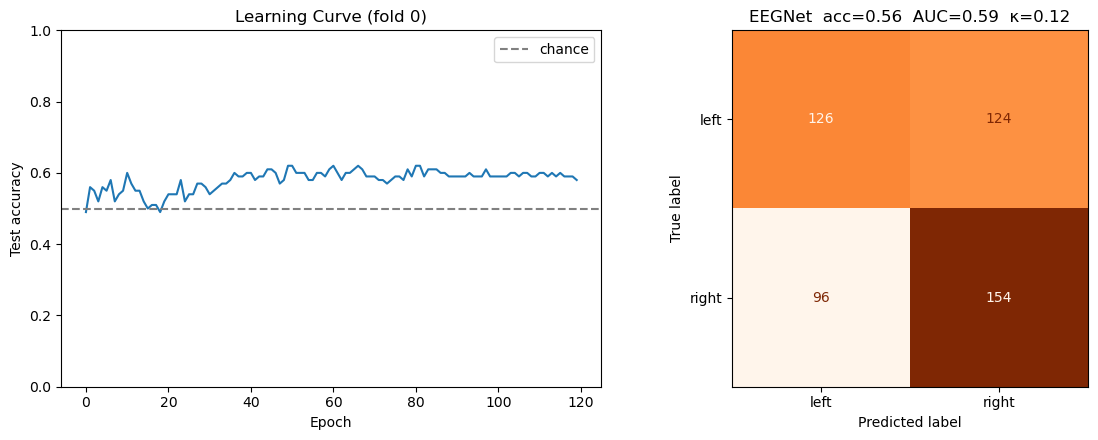

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(first_history)
ax1.set(xlabel="Epoch", ylabel="Test accuracy", title="Learning Curve (fold 0)", ylim=(0, 1))
ax1.axhline(0.5, color="gray", ls="--", label="chance")
ax1.legend()

cm = confusion_matrix(yt, yp)
ConfusionMatrixDisplay(cm, display_labels=[U.CLASS_NAMES[0], U.CLASS_NAMES[1]]).plot(
    cmap="Oranges", values_format="d", ax=ax2, colorbar=False)
ax2.set_title(f"EEGNet  acc={(yt==yp).mean():.2f}  AUC={auc:.2f}  κ={kappa:.2f}")
plt.tight_layout(); plt.show()

## 5. Summary and Exercises

**Improvements over the baseline**
| Change | Effect |
|---|---|
| `bandpass=(8,13)` — μ-band only | Concentrates on the band where motor imagery ERD is strongest |
| `epochs=120` (up from 60) | Small batches converge slowly; more iterations are needed |
| `CosineAnnealingLR` | Smoothly decays the learning rate for stable convergence |
| `weight_decay=1e-4` | L2 regularization to mildly reduce overfitting |

**Summary**
- μ-band filtering + LR scheduling improves EEGNet stability.
- The depthwise convolution learns **spatial filters** analogous to CSP — the two approaches
  share the same intuition.
- Despite this, EEGNet (~0.56 with leak-free 5-fold CV) does **not** match the classical
  methods from Notebook ① (FgMDM / μ-band CSP+LDA ~0.67). With only 100 trials this is
  expected: **deep learning needs an order of magnitude more data to truly shine.**
- Note the windows-per-trial overlap: because we split trials *before* windowing, this score
  is honest. Window-then-split would have reported a higher but **inflated** number.

**Exercises**
1. Set `use_scheduler=False`. How does the learning curve change?
2. Try `epochs=60` and `epochs=200`. Where is the boundary between underfitting and overfitting?
3. Adjust `WINDOW_S` and `STRIDE_S` (Section 1). How do window length and step affect accuracy?
4. Compare EEGNet accuracy here with FgMDM from Notebook ①. Rather than asking "which is better,"
   think about *why* they differ.